In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [ ]:
np.random.seed(42)
n = 500

study_hours = np.random.normal(5, 2, n).clip(0, 12)
attendance = np.random.normal(75, 15, n).clip(30, 100)
previous_score = np.random.normal(65, 12, n).clip(30, 100)
sleep_hours = np.random.normal(7, 1.5, n).clip(3, 10)
extra_activities = np.random.randint(0, 2, n)  # 0 = no, 1 = yes


exam_score = (
    study_hours * 5 +
    attendance * 0.3 +
    previous_score * 0.4 +
    sleep_hours * 1.5 -
    extra_activities * 2 +
    np.random.normal(0, 5, n)
).clip(0, 100)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_score': previous_score,
    'sleep_hours': sleep_hours,
    'extra_activities': extra_activities,
    'exam_score': exam_score
})

print(df.head())
print(df.describe())


   study_hours  attendance  previous_score  sleep_hours  extra_activities  \
0     5.993428   88.892663       81.792265     8.167542                 1   
1     4.723471  100.000000       76.095604     6.173221                 0   
2     6.295377   54.021486       65.715564     5.772702                 1   
3     8.046060   83.444539       57.236759     6.994938                 0   
4     4.531693   65.240361       73.378680     6.744723                 0   

   exam_score  
0  100.000000  
1   93.411170  
2   77.421175  
3  100.000000  
4   90.720872  
       study_hours  attendance  previous_score  sleep_hours  extra_activities  \
count   500.000000  500.000000      500.000000   500.000000        500.000000   
mean      5.015709   75.174634       66.301814     7.039610          0.512000   
std       1.947191   14.050944       12.122956     1.438488          0.500357   
min       0.000000   34.546700       30.244935     3.000000          0.000000   
25%       3.599385   66.070624      

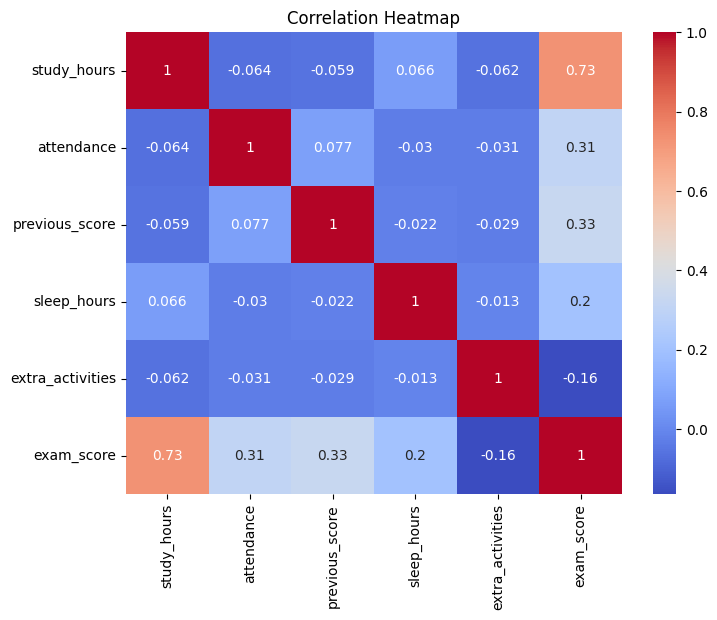

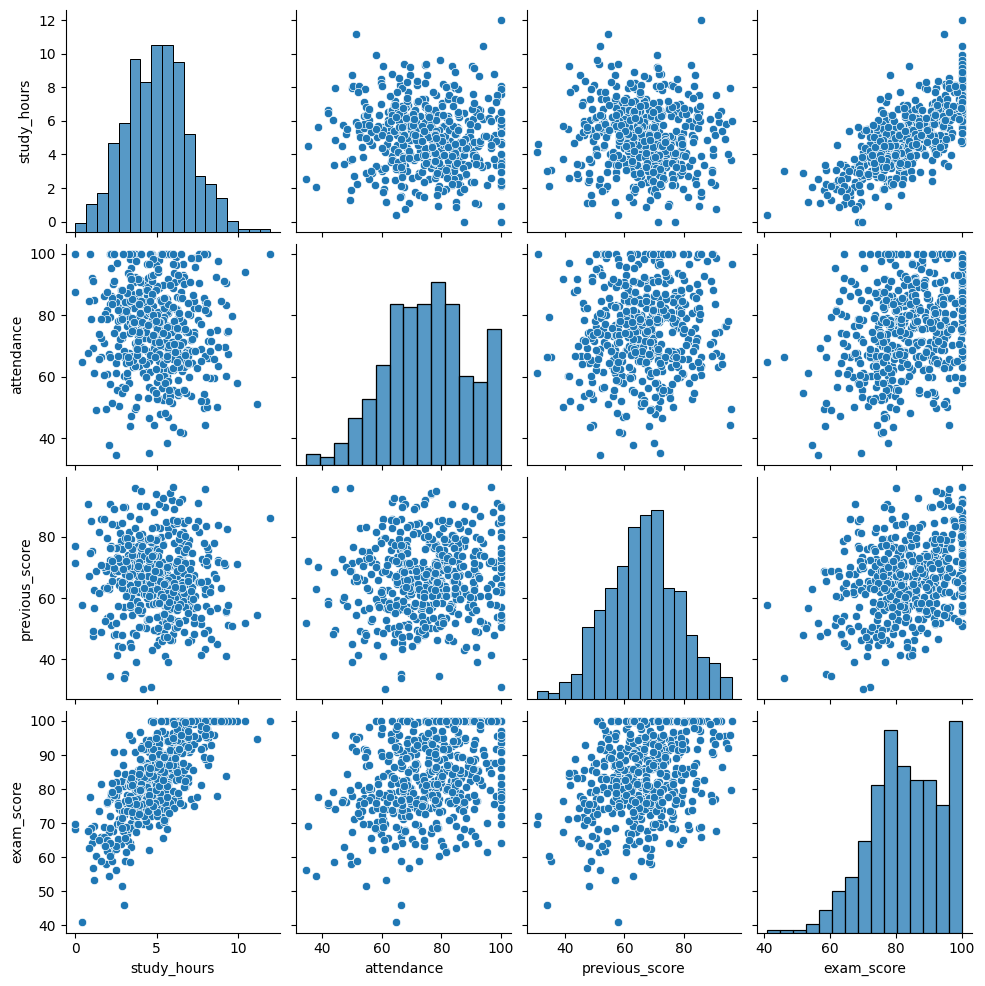

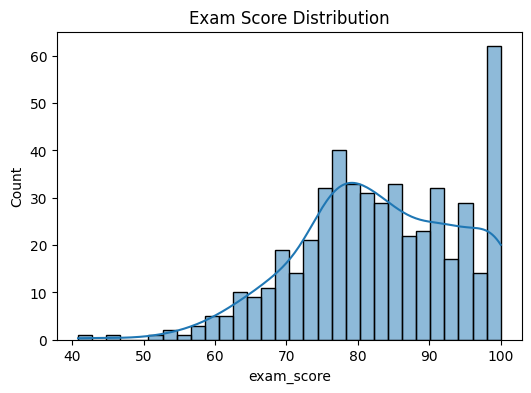

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

sns.pairplot(df[['study_hours','attendance','previous_score','exam_score']])
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df['exam_score'], bins=30, kde=True)
plt.title("Exam Score Distribution")
plt.show()


In [ ]:
X = df.drop('exam_score', axis=1)
y = df['exam_score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
rf_preds = rf.predict(X_test_scaled)


In [ ]:
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"\n--- {name} ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R2 Score: {r2:.4f}")

evaluate("Linear Regression", y_test, lr_preds)
evaluate("Random Forest", y_test, rf_preds)



--- Linear Regression ---
RMSE: 5.4867
MAE: 4.2363
R2 Score: 0.7243

--- Random Forest ---
RMSE: 4.8337
MAE: 3.9752
R2 Score: 0.7860


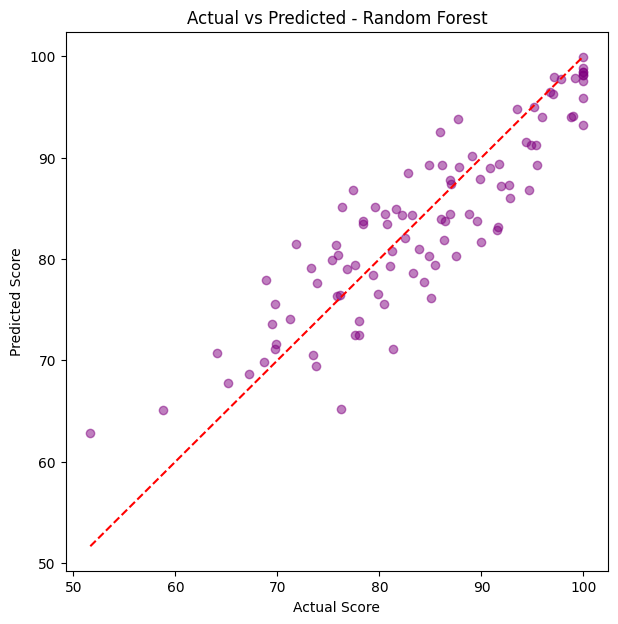

In [ ]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, rf_preds, alpha=0.5, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted - Random Forest")
plt.show()

In [ ]:
importances = rf.feature_importances_
feat_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances}).sort_values('Importance', ascending=False)
sns.barplot(data=feat_df, x='Importance', y='Feature')
plt.title("Feature Importance - Random Forest")
plt.show()


In [ ]:
new_student = pd.DataFrame({
    'study_hours': [6],
    'attendance': [85],
    'previous_score': [70],
    'sleep_hours': [7],
    'extra_activities': [0]
})
new_student_scaled = scaler.transform(new_student)
predicted_score = rf.predict(new_student_scaled)
print(f"Predicted Exam Score: {predicted_score[0]:.2f}")